# Part C: Prove the palette, do not claim it

This audit compares an initially chosen `matplotlib` `tab10` palette with the course palette. Every simulated swatch is generated by `vizlib.simulate_cvd`, and every closest-pair claim is measured with `vizlib.worst_pair`.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import colormaps

DATA = Path.cwd()
if not (DATA / 'vizlib.py').exists():
    DATA = DATA / 'Week 03'
sys.path.insert(0, str(DATA))
import vizlib

KINDS = ['protan', 'deutan', 'tritan']
tab10 = [colormaps['tab10'](i)[:3] for i in range(4)]
tab10 = ['#' + ''.join(f'{round(channel * 255):02X}' for channel in colour) for colour in tab10]
course_three = vizlib.PALETTE['series']
course_four = course_three + [vizlib.PALETTE['series_4th']]
palettes = {'tab10 first four': tab10, 'course four slots': course_four}
print('Rows removed: 0; palette audit uses all declared colour slots.')
print('Chosen palette before testing:', tab10)
print('Course palette:', course_four)

Rows removed: 0; palette audit uses all declared colour slots.
Chosen palette before testing: ['#1F77B4', '#FF7F0E', '#2CA02C', '#D62728']
Course palette: ['#0072B2', '#D55E00', '#009E73', '#CC79A7']


## 1–2. Before/after swatches under colour-vision simulation

The first palette is deliberately `tab10` rather than a palette assumed to be safe. Each row shows normal colours followed by the transformed colours for one deficiency type.

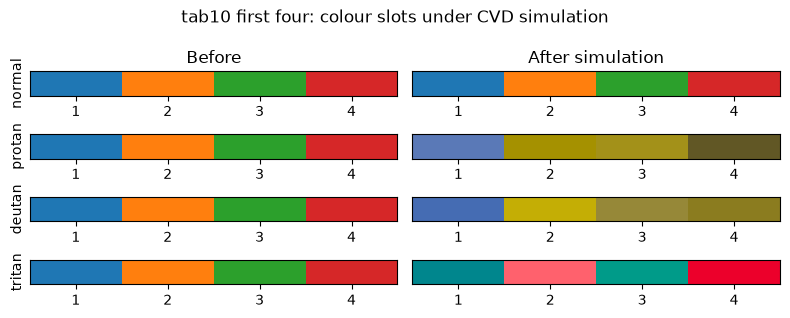

tab10 first four protan [('#1F77B4', '#5A79B7'), ('#FF7F0E', '#A59100'), ('#2CA02C', '#A39119'), ('#D62728', '#615725')]
tab10 first four deutan [('#1F77B4', '#456CB3'), ('#FF7F0E', '#C4AE05'), ('#2CA02C', '#968838'), ('#D62728', '#8B7C1F')]
tab10 first four tritan [('#1F77B4', '#00868D'), ('#FF7F0E', '#FF616D'), ('#2CA02C', '#009B89'), ('#D62728', '#EC002B')]


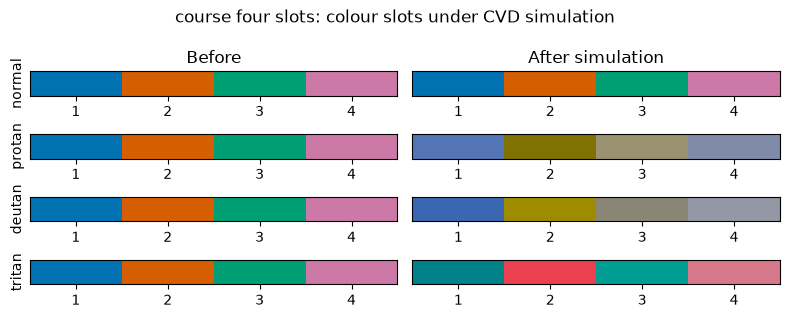

course four slots protan [('#0072B2', '#5375B5'), ('#D55E00', '#817100'), ('#009E73', '#9A9271'), ('#CC79A7', '#808BA9')]
course four slots deutan [('#0072B2', '#3B67B1'), ('#D55E00', '#9E8C00'), ('#009E73', '#8A8676'), ('#CC79A7', '#9498A5')]
course four slots tritan [('#0072B2', '#008289'), ('#D55E00', '#EB4050'), ('#009E73', '#009E92'), ('#CC79A7', '#D6788A')]


In [2]:
def swatch_row(colours):
    return np.array([[plt.matplotlib.colors.to_rgb(colour) for colour in colours]])

for palette_name, palette in palettes.items():
    fig, ax = plt.subplots(4, 2, figsize=(8, 3.2))
    rows = [('normal', palette)] + [(kind, vizlib.simulate_cvd(palette, kind)) for kind in KINDS]
    for row, (label, colours) in enumerate(rows):
        ax[row, 0].imshow(swatch_row(palette), aspect='auto')
        ax[row, 1].imshow(swatch_row(colours), aspect='auto')
        ax[row, 0].set_ylabel(label)
        for column in range(2):
            ax[row, column].set_xticks(range(len(palette)), range(1, len(palette) + 1))
            ax[row, column].set_yticks([])
    ax[0, 0].set_title('Before')
    ax[0, 1].set_title('After simulation')
    fig.suptitle(f'{palette_name}: colour slots under CVD simulation')
    fig.tight_layout()
    filename = '03_tab10_cvd_swatches.png' if palette_name.startswith('tab10') else '03_course_cvd_swatches.png'
    fig.savefig(DATA / 'figures' / filename, dpi=150, bbox_inches='tight')
    plt.show()
    for kind in KINDS:
        print(palette_name, kind, list(zip(palette, vizlib.simulate_cvd(palette, kind))))

## 3. Worst-pair ΔE audit

The closest pair is reported for normal vision and for each simulated deficiency. ΔE below 8 requires a redundant channel; the fourth course slot is not safe for colour-only encoding.

In [3]:
reports = []
for palette_name, palette in palettes.items():
    for kind in ['normal'] + KINDS:
        pair = vizlib.worst_pair(palette, None if kind == 'normal' else kind)
        reports.append({
            'palette': palette_name,
            'vision': kind,
            'slots': f'{pair[0]}–{pair[1]}',
            'colours': f'{pair[2]} / {pair[3]}',
            'worst_delta_e': pair[4],
        })
report = pd.DataFrame(reports)
print(report.round({'worst_delta_e': 2}).to_string(index=False))
print('\nInterpretation: the course fourth slot is the closest/weakest slot under CVD, so it must not carry category identity by colour alone.')
print('Use direct labels, a table, a distinct marker, or a separate panel whenever that fourth slot is needed.')

          palette vision slots           colours  worst_delta_e
 tab10 first four normal   2–4 #FF7F0E / #D62728          18.60
 tab10 first four protan   2–3 #FF7F0E / #2CA02C           0.68
 tab10 first four deutan   3–4 #2CA02C / #D62728           4.06
 tab10 first four tritan   1–3 #1F77B4 / #2CA02C           6.72
course four slots normal   2–4 #D55E00 / #CC79A7          16.42
course four slots protan   1–4 #0072B2 / #CC79A7           9.49
course four slots deutan   3–4 #009E73 / #CC79A7           7.55
course four slots tritan   1–3 #0072B2 / #009E73           8.37

Interpretation: the course fourth slot is the closest/weakest slot under CVD, so it must not carry category identity by colour alone.
Use direct labels, a table, a distinct marker, or a separate panel whenever that fourth slot is needed.


## 4. Rule for more than three categories

For the rest of the course, I will not add a fourth or larger colour-only categorical palette. I will use small multiples or direct labels, and add marker shape, line style, or a table as a redundant identity channel. The course fourth hue may be used only with that redundancy; it is not allowed to carry identity alone.

In [4]:
assert set(KINDS) == {'protan', 'deutan', 'tritan'}
assert len(report) == 8
assert all(vizlib.worst_pair(course_four, kind)[-1] > 0 for kind in KINDS)
print('Audit checks passed: both palettes were simulated for protan, deutan, and tritan; all pairwise worst-pair reports were computed.')

Audit checks passed: both palettes were simulated for protan, deutan, and tritan; all pairwise worst-pair reports were computed.
